## Import librairies

In [3]:
import os.path as _ospath
import h5py as h5py
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tkinter as tk
import tkinter.filedialog
import yaml
from scipy.interpolate import interpn
from scipy.interpolate import interp1d
import h5py
import math
from sklearn import cluster, datasets, mixture

## Functions

In [4]:
########################
### Rotate locations ###
########################

def rotate_data_multi_selection(yaml_file_name, location_file_name, i):
    with open(yaml_file_name) as file_y:
    #file_y = path+yaml_file+band_num_str+yaml_n
        pick = yaml.load(file_y, Loader=yaml.FullLoader)   
    location_file_data_all_selection =pd.read_hdf(location_file_name, key='locs')
    cond = location_file_data_all_selection['group'] == i
    location_file_data = location_file_data_all_selection[cond]
    unit_vector_x = [1,0] # x -axis unit vector
    unit_vector_y = [0,1] # y -axis unit vector
    vector_2 = [0,0] # empty vector. Will be the vertor of the pick.
    index = int(i)
    vector_2[0] = pick['Center-Axis-Points'][index][1][0] - pick['Center-Axis-Points'][index][0][0]
    vector_2[1] = pick['Center-Axis-Points'][index][1][1] - pick['Center-Axis-Points'][index][0][1]

    # Determine the angle in between the two vectors
    unit_vector_2 = vector_2 / np.linalg.norm(vector_2)
    
    dot_product_x = np.dot(unit_vector_x, unit_vector_2)
    dot_product_y = np.dot(unit_vector_y, unit_vector_2)
    a = -np.sign(np.sin(dot_product_y))*np.arccos(dot_product_x) #rotation angle
    vector_middle_pick = [0,0]

    vector_middle_pick[0] = pick['Center-Axis-Points'][i][0][0] + vector_2[0]/2
    vector_middle_pick[1] = pick['Center-Axis-Points'][i][0][1] + vector_2[1]/2

    #move center of pick to orign
    location_file_data.loc[:,"x"] -= vector_middle_pick[0]
    location_file_data.loc[:,"y"]-= vector_middle_pick[1]

    x_copy = np.copy(location_file_data.loc[:,"x"])
    y_copy = np.copy(location_file_data.loc[:,"y"])

    #rotate data
    location_file_data.loc[:,"x"] = x_copy*np.cos(a) - y_copy*np.sin(a)
    location_file_data.loc[:,"y"] = x_copy*np.sin(a) + y_copy*np.cos(a)

    # shift pick that x.min = 0 and y.min = 0
    location_file_data.loc[:,"x"] -= location_file_data.x.min()
    location_file_data.loc[:,"y"] -= location_file_data.y.min()

    return location_file_data



#################################################################
### Display entire selection (myofibril) ans selected z-disks ###
#################################################################
def display_myofibril(location_file_data, size = 0.2):
    location_file_data = file
    x = file.x
    y = file.y
    #xy = np.vstack([x,y])
    #z = gaussian_kde(xy)(xy)
    miny = min(y)-3
    binx = int((max(x)-min(x))*1.5)
    biny = int((max(y)-min(y))*1.5)
    #bins=200 # defines how data should be binned in(bins x bins) 2d hist
    data , x_e, y_e = np.histogram2d( x, y, bins = [binx, biny], density = True )
    z = interpn( ( 0.5*(x_e[1:] + x_e[:-1]) , 0.5*(y_e[1:]+y_e[:-1]) ) ,
            data , np.vstack([x,y]).T , method = "splinef2d", bounds_error = False)
    
    fig, ax = plt.subplots(figsize=(15,4))
    #ax.scatter(x, y, c=z,cmap = 'summer', s=1, edgecolor='')
    ax.scatter(x, y, s=size, c =z, cmap = 'summer')#, edgecolor='')
    ax.set_facecolor("black")
    ax.set_aspect(1)
    plt.show()
    
###################################################################################################################
###  Filter locations based on a parameter to put in (standard deviation by default, lp or others can be used)  ###
###################################################################################################################

def filter_loc(location_file_data, tofilter = 's',center = 0.95, radius = 0.05, adaptive_filter = False):
    center_x = center
    center_y = center
    
    locs = location_file_data
    tofilter_x = tofilter + 'x'
    tofilter_y = tofilter + 'y'
    
    x = locs[tofilter_x]
    y = locs[tofilter_y]
    
    pre_keep = (x-center)**2 + (y-center)**2 < (8*radius)**2
    pre_filtered_locs = locs[pre_keep]
    
    pre_x = pre_filtered_locs[tofilter_x]
    pre_y = pre_filtered_locs[tofilter_y]
    
    binx = 10
    biny = 10
    #bins=200 # defines how data should be binned in(bins x bins) 2d hist
    data , x_e, y_e = np.histogram2d( pre_x, pre_y, bins = [binx, biny], density = True )
    z = interpn( ( 0.5*(x_e[1:] + x_e[:-1]) , 0.5*(y_e[1:]+y_e[:-1]) ) ,
            data , np.vstack([pre_x,pre_y]).T , method = "splinef2d", bounds_error = False)
    
    if adaptive_filter == True:
        #select points along the first diagonal
        diag_keep = (x-radius/10 < y) & (x+radius/10 > y)
        diag_filtered_locs = pre_filtered_locs[diag_keep]
        diag_x = diag_filtered_locs[tofilter_x]
        diag_y = diag_filtered_locs[tofilter_y]

        min_diag_x =  np.min(diag_x)
        max_diag_x =  np.max(diag_x)
        bins_diag = round((max_diag_x-min_diag_x)/radius*5)
        # histogram of positions along the x axis
        h_diag = np.histogram(diag_x, bins = bins_diag)
        step = (h_diag[1][1]-h_diag[1][0])
        
        h_diag_x = h_diag[1][:len(h_diag[1])-1]+step/2
        f = interp1d(h_diag_x, h_diag[0], kind='cubic')
        xnew = np.linspace(min_diag_x+step, max_diag_x-step, num=10*bins_diag, endpoint=True)
        
        center_x = xnew[f(xnew).argmax()]
        min_diag_y =  np.min(diag_y)
        max_diag_y =  np.max(diag_y)
        bins_diag = round((max_diag_y-min_diag_y)/radius*5)
        # histogram of positions along the y axis
        h_diag = np.histogram(diag_y, bins = bins_diag)
        step = (h_diag[1][1]-h_diag[1][0])
        h_diag_y = h_diag[1][:len(h_diag[1])-1]+step/2
        f = interp1d(h_diag_y, h_diag[0], kind='cubic')
        xnew = np.linspace(min_diag_y+step, max_diag_y-step, num=10*bins_diag, endpoint=True)
        center_y = xnew[f(xnew).argmax()]
        
    fig, ax = plt.subplots(figsize=(5,5))
    #ax.scatter(x, y, c=z,cmap = 'summer', s=1, edgecolor='')
    ax.scatter(pre_x, pre_y, s=.2, c =z, cmap = 'summer')#, edgecolor='')
    ax.set_ylim(center_y - radius*5,center_y + radius*5)
    ax.set_xlim(center_x - radius*5,center_x + radius*5)
    ax.set_facecolor("black")
    ax.set_title('Filtering selection for '+ tofilter + 'x and ' +tofilter+ 'y')
    circle_filter = plt.Circle([center_x,center_y], radius, edgecolor = 'red', fill = False, lw = 2)
    ax.add_patch(circle_filter)
    ax.set_xlabel(tofilter + 'x')
    ax.set_ylabel(tofilter + 'y')
    #sets aspect ratio to 1
    ax.set_aspect(1)
    plt.show()

    to_keep = (x-center_x)**2 + (y-center_y)**2 < radius**2
    filtered_locs = locs[to_keep]
    #print('Length of locs before filtering {}, after filtering {}.'.format(len(locs),len(filtered_locs)))
    
    return filtered_locs


###############################################
###  Get dataset info out of the file name  ###
###############################################

def get_data_info(locfile):############## Version for 2019 data
    #get the file name without extension
    loc_file_name = os.path.splitext(os.path.basename(locfile))[0] 
    
    #split the file name with '_'
    specs = loc_file_name.split('_')
    day = specs[0]
    sample = specs[1].lstrip("sample")
    fly_number = specs[2]
    selection = ""
    probe = ""
    dye = specs[4]
    imager_concentration = specs[5]
    laser_power = specs[6]
    return day, sample, fly_number, selection, probe, dye, imager_concentration, laser_power



#############################################################
###  Filter events that spend "too" long on the coverslip ###
###  based on DBSCAN in x, y, frame space
#############################################################

def filtering_long_lived_events(file, epsilon = 1., scaling = 0.1, limit_lifetime = 25):
    #epsilon: radius in x, y, frame space used to define a cluster. frame axis is scaled by the next parameter scaling
    #limit_lifetime: maximum lifetime of an event expressed in frames

    scaled_t = np.array(file.frame)*scaling
    X = np.column_stack([scaled_t, file.x, file.y])

    db = cluster.DBSCAN(eps=epsilon, min_samples=1).fit(X) # Clustering with DBSCAN
    core_samples_mask = np.zeros_like(db.labels_, dtype=bool)
    core_samples_mask[db.core_sample_indices_] = True
    labels = db.labels_

    # singleton are labeled -1
    labels_cor = filter(lambda n: n > -1, labels)
    #define Series
    data = pd.Series(labels_cor)

    #find frequencies of each value
    lifetimes = data.value_counts()
    lifetime_df = lifetimes.to_frame()

    lifetimes = np.array(lifetime_df.iloc[:,0])
    cluster_number = np.array(lifetime_df.index)

    # idetifies clusters based on maximum lifetime
    clusters_to_filter_out = []
    for i in range(len(lifetimes)):
        if lifetimes[i] > limit_lifetime:
            clusters_to_filter_out = np.append(clusters_to_filter_out, cluster_number[i])

    file['label'] = labels
    df_filtered = file[~file['label'].isin(clusters_to_filter_out)]
    
    return df_filtered

def average_position_of_multiframe_events(file, epsilon = 1., scaling = 0.1):
    scaled_t = np.array(file.frame)*scaling
    X = np.column_stack([scaled_t, file.x, file.y])
    db = cluster.DBSCAN(eps=epsilon, min_samples=2).fit(X)

    core_samples_mask = np.zeros_like(db.labels_, dtype=bool)
    core_samples_mask[db.core_sample_indices_] = True
    labels = db.labels_
    
    file_filtered_singleton = file[file['label'].isin([-1])]
    file_filtered_mean = file[~file['label'].isin([-1])]

    mylist = list(file_filtered_mean)# get names of all columns
    file_filtered_mean.index.names = ['index']
    file_filtered_mean = file_filtered_mean.groupby('label')[mylist].mean()
    
    concat_file = pd.concat([file_filtered_mean, file_filtered_singleton])
    
    return concat_file

def filter_smaller_clusters(file, epsilon = 1., sd = 1.5):
    X = np.column_stack([file.x, file.y])

    db = cluster.DBSCAN(eps=epsilon, min_samples=5).fit(X)
    core_samples_mask = np.zeros_like(db.labels_, dtype=bool)
    core_samples_mask[db.core_sample_indices_] = True
    labels = db.labels_
    file['label'] = labels

    #get rid off singleton
    concat_file_wo_singleton = file[~file['label'].isin([-1])]
    sd_per_group = concat_file_wo_singleton.groupby('label')[['x', 'y']].std()#apply(lambda x: np.std(x))
    sd_per_group['label'] = np.unique(concat_file_wo_singleton['label'])
    sd_per_group['total_sd'] = np.sqrt(sd_per_group['x']**2 + sd_per_group['y']**2)
    
    sd_per_group_cor = sd_per_group[sd_per_group['total_sd'] > sd]
    label_cor = sd_per_group_cor['label']
    locs_filtered = concat_file_wo_singleton[concat_file_wo_singleton['label'].isin(label_cor)]

    return locs_filtered


## Load picked regions

In [8]:
root = tk.Tk()
loc_filename = tk.filedialog.askopenfilename(parent=root, title='Please select the first selection hdf5 location file')
yaml_region_filename = tk.filedialog.askopenfilename(parent=root, title='Please select the first yaml picks region file')
root.withdraw()

''

E:/2026_02_18_keep/Analysis/20260218_sample3_1_Nb37_P3_Cy3B_2nM_Phall488_XmW_picasso_20230418_3_filter_render_picked.hdf5
 Myofibril 1
 Myofibril before filtering, number of localizations = 34692


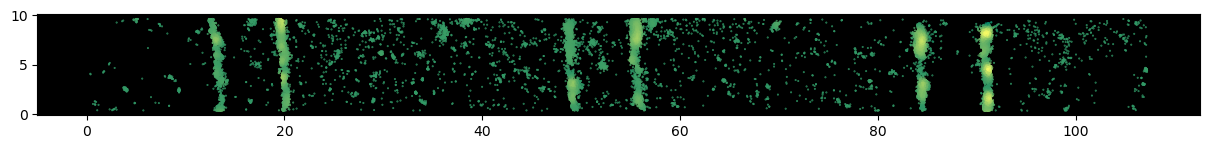

 Myofibril after filtering , number of localizations = 8051, 23.21% left


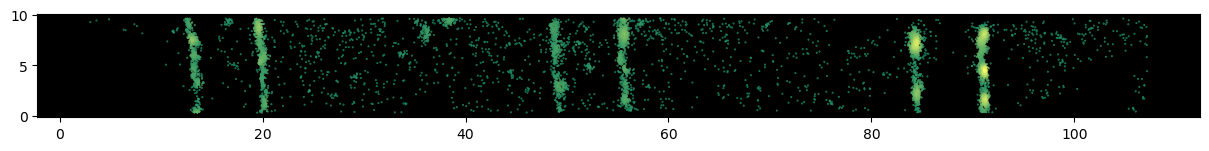

 Myofibril 2
 Myofibril before filtering, number of localizations = 30385


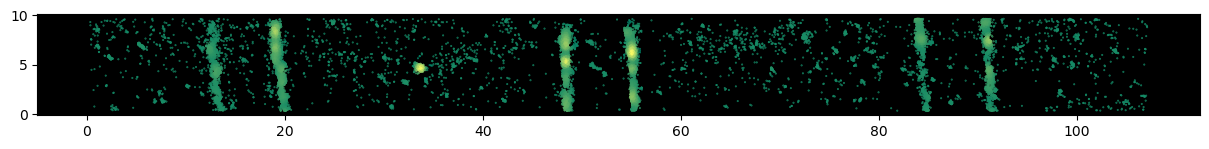

 Myofibril after filtering , number of localizations = 7585, 24.96% left


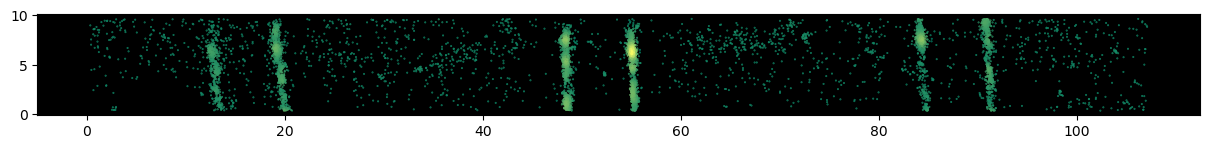

 Myofibril 3
 Myofibril before filtering, number of localizations = 36586


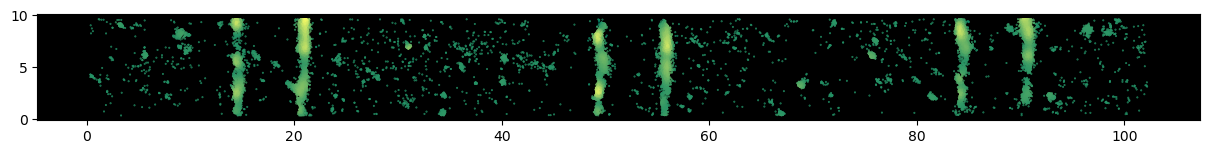

 Myofibril after filtering , number of localizations = 10010, 27.36% left


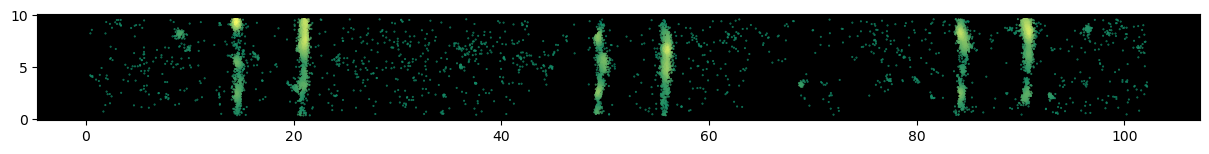

In [9]:
#for filtering
#epsilon: radius in x, y, frame space used to define a cluster. frame axis is scaled by the next parameter scaling
#limit_lifetime: maximum lifetime of an event expressed in frames
epsilon_ = 1.5#1.5
scaling_ = 1.0#0.05
limit_lifetime_ = 25

#min_sd: parameter used to define the minimum size kept for a band
min_sd = 1.5
distances_all = []

data_frame_to_save = pd.DataFrame(columns = ['sample', 'fly_number', 'selection','probe','dye','zdisk', 'band_distance',
                               'band_positions','band_widths','band_widths_estimate'])

location_file_data =pd.read_hdf(loc_filename, key='locs')
selections = location_file_data.group.unique()

#data_frame_to_save = pd.DataFrame()

print(loc_filename)

for i in range(len(selections)):
    print("\033[32m Myofibril " + str(i+1) + "\033[m") # myofibril number to be analyzed
    #print(loc_files[i])
    
    file = rotate_data_multi_selection(yaml_region_filename,loc_filename, i) #rotate region of interest to get it horizontal

    before = len(file)
    
    print("\033[32m Myofibril before filtering\033[m" + ", number of localizations = " + str(len(file) ))
    display_myofibril(file, size = 0.2)
    #filter localization based on localization standard deviation or precision of localization
    #file = filter_loc(file, 's', 0.2, 1, True)#0.2 for DECODE
    file = filtering_long_lived_events(file, epsilon = epsilon_, scaling = scaling_, limit_lifetime = limit_lifetime_)
    
    # replace all events happening on multiple frames (at least 2) into a single event,
    # which characteristics are the average of all localizations consired being a single binding event
    file = average_position_of_multiframe_events(file, epsilon = epsilon_, scaling = scaling_)
    
    # filter out all events that are considered too small in size
    file = filter_smaller_clusters(file, epsilon = epsilon_, sd = min_sd)
    if len(file) != 0:
        print("\033[32m Myofibril after filtering \033[m" + ", number of localizations = " + str(len(file)) + ", " + 
              str(round(len(file)/before*100, 2)) + "% left" )
        display_myofibril(file, size = 0.2)

        #remove useless columns
        # dont use index prob for OLD hemi-thorax data
        file = file.drop([ 'x_pick_rot', 'y_pick_rot', 'label', 'group'], axis=1) 
        #get frame as int
        file['frame'] = pd.to_numeric(file['frame'], downcast='integer', errors='coerce')
        
        ### Height and width
        hw = np.max(np.array([math.ceil(file['x'].max()), math.ceil(file['y'].max())]))
        
        height = hw
        width = hw
        
        frames = int(np.max(file['frame']) + 1)
        dict_file = {'Frames':frames, 'Height':height, 'Width':width}
        
        locs = file.to_records(index=False)# transform pandas dataframe to recarray
        
        base, ext = _ospath.splitext(loc_filename)
        new_path = base + '_DBSCAN_2_#' + str(i+1) + '.hdf5'
        
        with h5py.File(new_path, "w") as locs_file:
            locs_file.create_dataset("locs", data=locs)
        
        new_path = base + '_DBSCAN_2_#' + str(i+1) + '.yaml'
        with open(new_path, 'w') as file:
            yaml.dump(dict_file, file)
    
       
        ########## TO ADD: ANALYSIS OF WIDTH BASED ON STRAIGHTENED BANDS THROUGH CROSSCORRELATION
        ########## Try estimating width based on multiple location fitting along a band
        ########## (with threshold on number of event at a given location for good estimate))


In [15]:
!pip install tables

   ---------------------------------------- 0.0/3.6 MB ? eta -:--:--
   -------------- ------------------------- 1.3/3.6 MB 8.4 MB/s eta 0:00:01
   -------------------------------- ------- 2.9/3.6 MB 7.6 MB/s eta 0:00:01
   ---------------------------------------- 3.6/3.6 MB 7.3 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ------------------------------------- -- 1.8/2.0 MB 8.4 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 8.3 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ------------------------------ --------- 2.1/2.8 MB 10.7 MB/s eta 0:00:01
   ---------------------------------------- 2.8/2.8 MB 8.5 MB/s eta 0:00:00
